# Machine Learning-Based Prediction of 30-Day Hospital Readmission in Diabetic Patients

## Exploratory Data Analysis

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/2. interim/cleaned.csv")

### Basic Dataset Overview

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 47 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   patient_nbr               101766 non-null  int64 
 1   race                      101766 non-null  object
 2   gender                    101766 non-null  object
 3   age                       101766 non-null  object
 4   admission_type            101766 non-null  object
 5   discharge_disposition     101766 non-null  object
 6   admission_source          101766 non-null  object
 7   time_in_hospital          101766 non-null  int64 
 8   payer_code                101766 non-null  object
 9   medical_specialty         101766 non-null  object
 10  num_lab_procedures        101766 non-null  int64 
 11  num_procedures            101766 non-null  int64 
 12  num_medications           101766 non-null  int64 
 13  number_outpatient         101766 non-null  int64 
 14  numb

In [5]:
df.describe()

,patient_nbr,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,5.433040e+07,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,3.869636e+07,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.350000e+02,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.341322e+07,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.550514e+07,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,8.754595e+07,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,1.895026e+08,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [6]:
df.describe(include='object')

,race,gender,age,admission_type,discharge_disposition,admission_source,payer_code,medical_specialty,diag_1,diag_2,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,6,3,10,6,25,15,18,73,12,12,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),Emergency,Discharged to home,Emergency Room,Unknown,Unknown,Circulatory,Circulatory,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,53990,60234,57494,40256,49949,30336,31365,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


### Target Variable Analysis

In [7]:
# Cheking target variable

df['readmitted'].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [8]:
df['readmitted'].value_counts(normalize=True)*100

readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

<Axes: xlabel='readmitted', ylabel='count'>

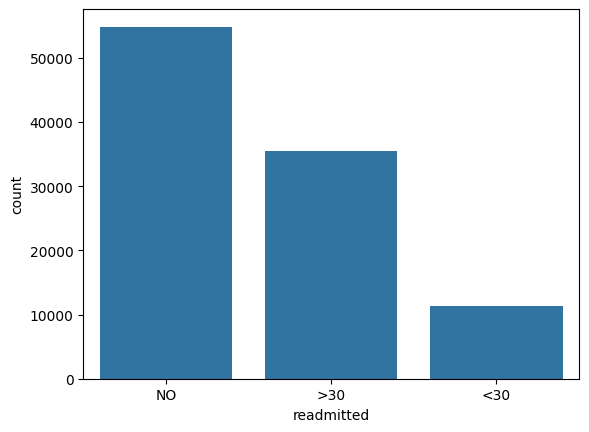

In [9]:
# Distribution of Target Column

sns.countplot(data=df, x='readmitted')

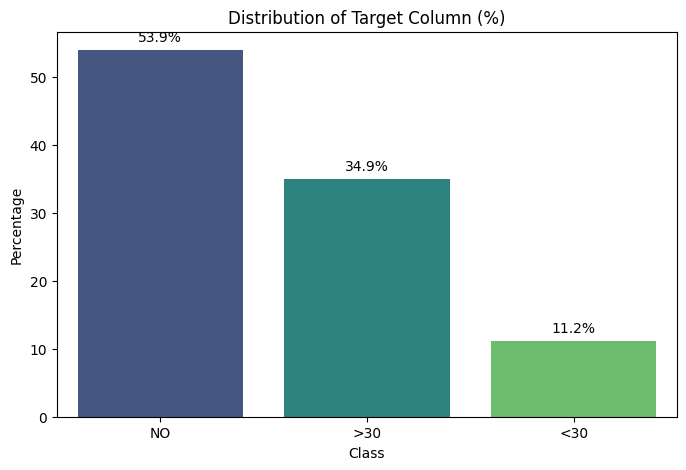

In [10]:
# 1. Calculate percentages
counts = df['readmitted'].value_counts(normalize=True).reset_index()
counts.columns = ['Class', 'Percentage']
counts['Percentage'] *= 100  # Convert to 0-100 scale

# 2. Plot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=counts,
    x='Class',
    y='Percentage',
    hue='Class',
    palette='viridis',
    legend=False
)

# 3. Add labels on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 9), 
                textcoords='offset points')

plt.title('Distribution of Target Column (%)')
plt.ylabel('Percentage')
plt.show()

In [11]:
# Insights

# Approximately 11.16% of encounters are labelled <30, making it the positive class (class 1) for this project.
# The negative class (class 0) combines encounters labelled "NO" and ">30".
# Therefore, the binary target is imbalanced, with fewer positive-class encounters than negative-class encounters.

In [12]:
df['readmitted_30d'] = df['readmitted'].eq('<30').astype('int8')

numeric_cols = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]

# Descriptive summary by binary outcome; this is not a causal analysis.
print(df.groupby('readmitted_30d')[numeric_cols].agg(['mean', 'median']).T)

readmitted_30d                     0          1
time_in_hospital   mean     4.349224   4.768249
                   median   4.000000   4.000000
num_lab_procedures mean    42.953644  44.226028
                   median  44.000000  45.000000
num_procedures     mean     1.347123   1.280884
                   median   1.000000   1.000000
num_medications    mean    15.911137  16.903143
                   median  15.000000  16.000000
number_outpatient  mean     0.360871   0.436911
                   median   0.000000   0.000000
number_emergency   mean     0.177803   0.357313
                   median   0.000000   0.000000
number_inpatient   mean     0.561648   1.224003
                   median   0.000000   0.000000
number_diagnoses   mean     7.388667   7.692789
                   median   8.000000   9.000000


### Numerical Feature Analysis

In [13]:
# important numerical columns
# ----------------------------
# time_in_hospital
# num_lab_procedures
# num_procedures
# num_medications
# number_outpatient
# number_emergency
# number_inpatient
# number_diagnoses

#### time_in_hospital

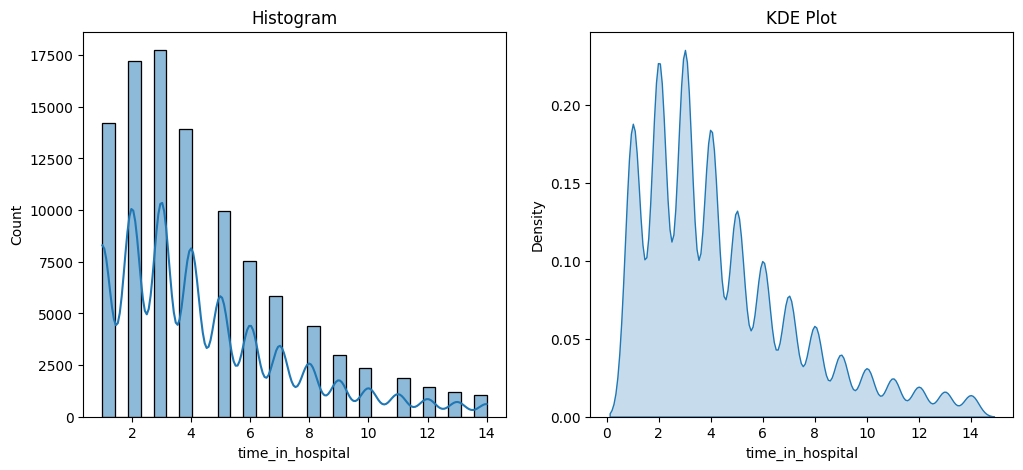

In [14]:
# time_in_hospital

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['time_in_hospital'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['time_in_hospital'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='time_in_hospital'>

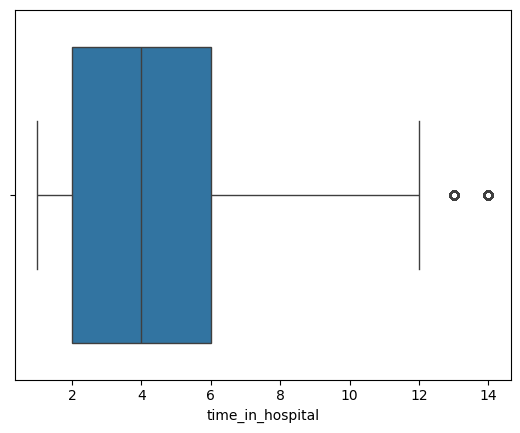

In [15]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['time_in_hospital'])

In [16]:
# 3. Mean/Median

print(f"Mean : {df['time_in_hospital'].mean()}")
print(f"Median : {df['time_in_hospital'].median()}")

Mean : 4.395986871843248
Median : 4.0


In [17]:
# 4. Filtering Outlier using IQR

Q1 = df['time_in_hospital'].quantile(0.25)
Q3 = df['time_in_hospital'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['time_in_hospital'] < lower_bound) | (df['time_in_hospital'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 2252


<Axes: xlabel='readmitted', ylabel='time_in_hospital'>

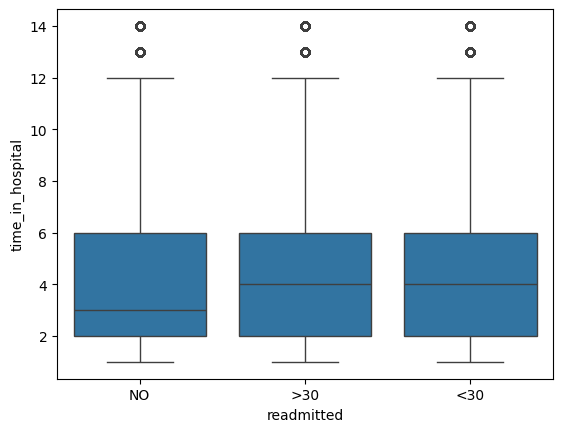

In [18]:
# Compare hospital stay duration across readmission categories.

sns.boxplot(x='readmitted', y='time_in_hospital', data=df)

#### num_lab_procedures

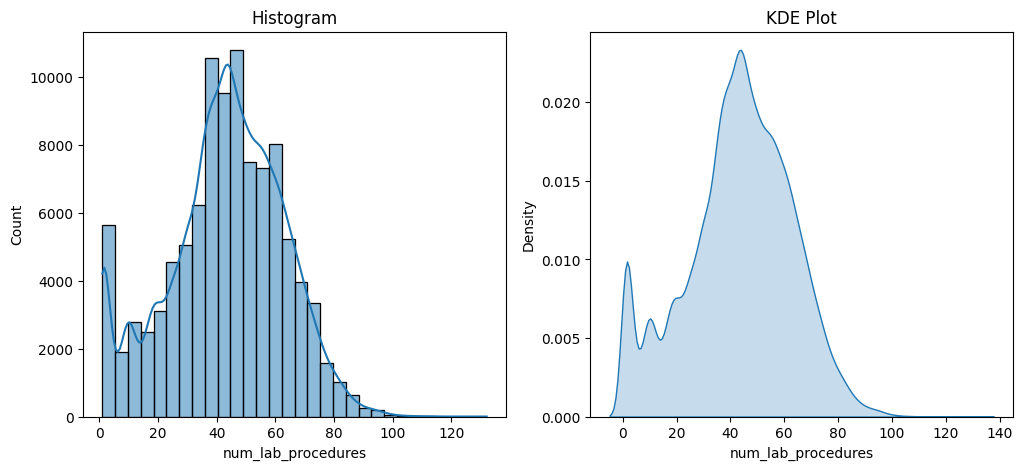

In [19]:
# num_lab_procedures

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['num_lab_procedures'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['num_lab_procedures'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='num_lab_procedures'>

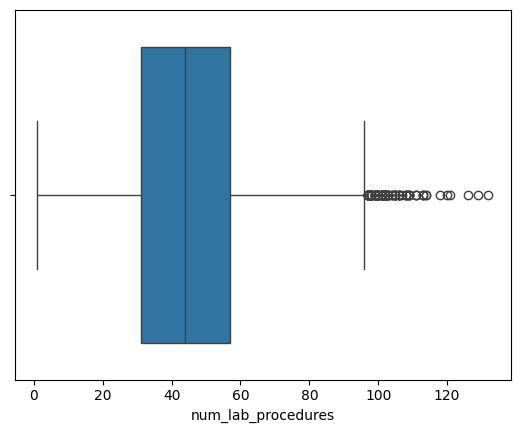

In [20]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['num_lab_procedures'])

In [21]:
# 3. Mean/Median

print(f"Mean : {df['num_lab_procedures'].mean()}")
print(f"Median : {df['num_lab_procedures'].median()}")

Mean : 43.09564098028811
Median : 44.0


In [22]:
# 4. Filtering Outlier using IQR

Q1 = df['num_lab_procedures'].quantile(0.25)
Q3 = df['num_lab_procedures'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['num_lab_procedures'] < lower_bound) | (df['num_lab_procedures'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 143


<Axes: xlabel='readmitted', ylabel='num_lab_procedures'>

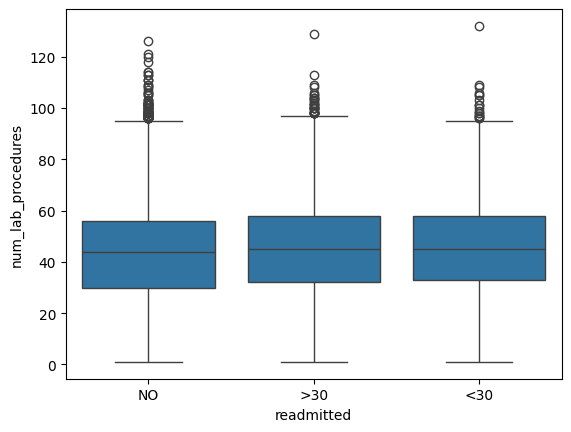

In [23]:
# Compare the number of laboratory procedures across readmission categories.

sns.boxplot(x='readmitted', y='num_lab_procedures', data=df)

#### num_procedures

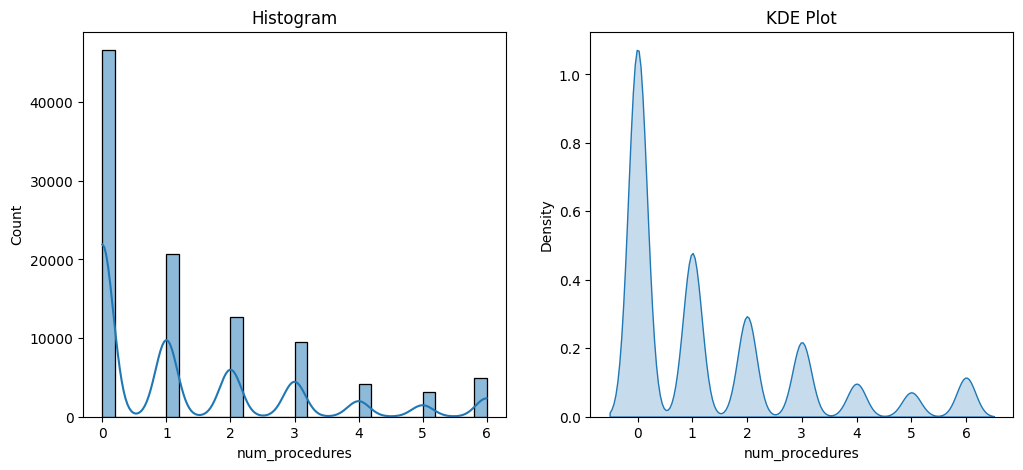

In [24]:
# num_procedures

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['num_procedures'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['num_procedures'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='num_procedures'>

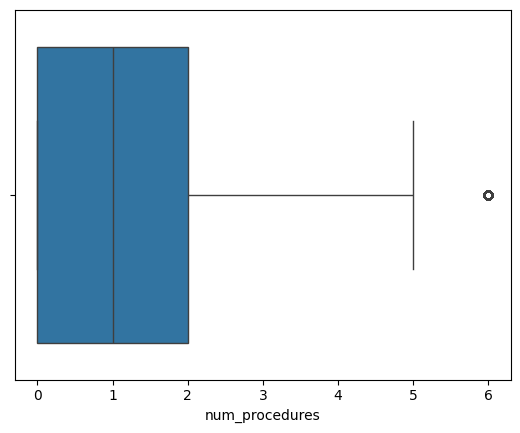

In [25]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['num_procedures'])

In [26]:
# 3. Mean/Median

print(f"Mean : {df['num_procedures'].mean()}")
print(f"Median : {df['num_procedures'].median()}")

Mean : 1.339730361810428
Median : 1.0


In [27]:
# 4. Filtering Outlier using IQR

Q1 = df['num_procedures'].quantile(0.25)
Q3 = df['num_procedures'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['num_procedures'] < lower_bound) | (df['num_procedures'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 4954


<Axes: xlabel='readmitted', ylabel='num_procedures'>

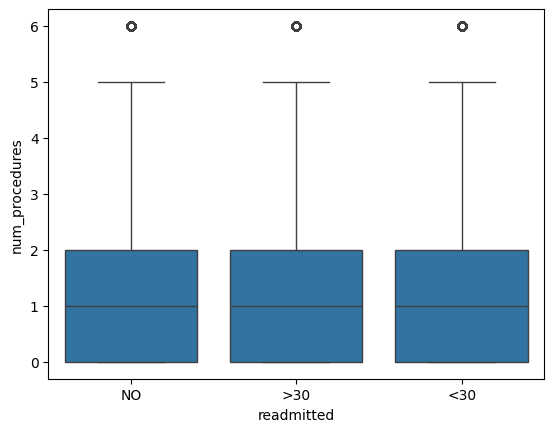

In [28]:
# Compare the number of procedures across readmission categories.

sns.boxplot(x='readmitted', y='num_procedures', data=df)

#### num_medications

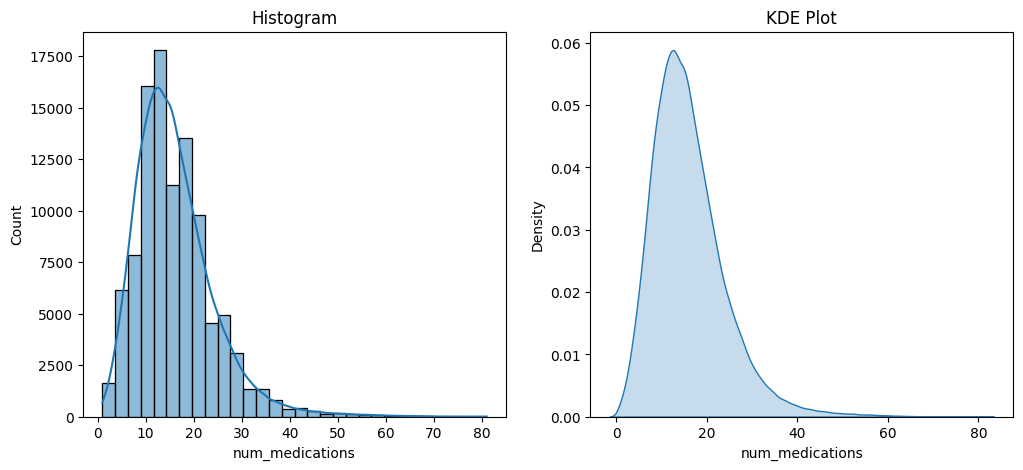

In [29]:
# num_medications

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['num_medications'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['num_medications'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='num_medications'>

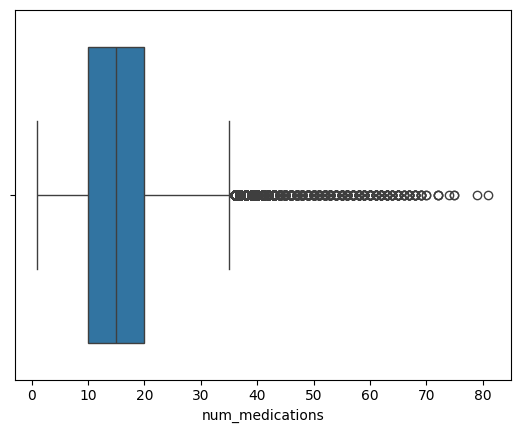

In [30]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['num_medications'])

In [31]:
# 3. Mean/Median

print(f"Mean : {df['num_medications'].mean()}")
print(f"Median : {df['num_medications'].median()}")

Mean : 16.021844230882614
Median : 15.0


In [32]:
# 4. Filtering Outlier using IQR

Q1 = df['num_medications'].quantile(0.25)
Q3 = df['num_medications'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['num_medications'] < lower_bound) | (df['num_medications'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 2557


<Axes: xlabel='readmitted', ylabel='num_medications'>

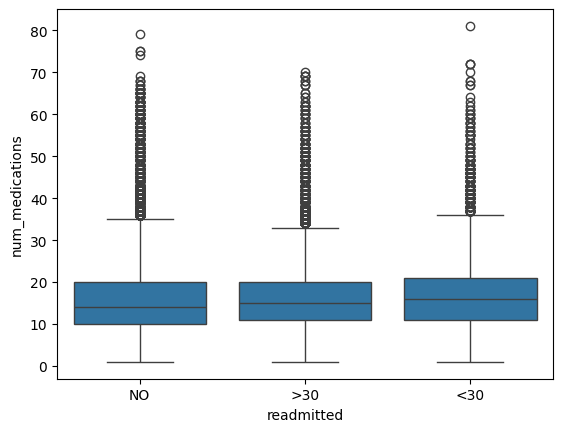

In [33]:
# Compare the number of medications across readmission categories.

sns.boxplot(x='readmitted', y='num_medications', data=df)

#### number_outpatient

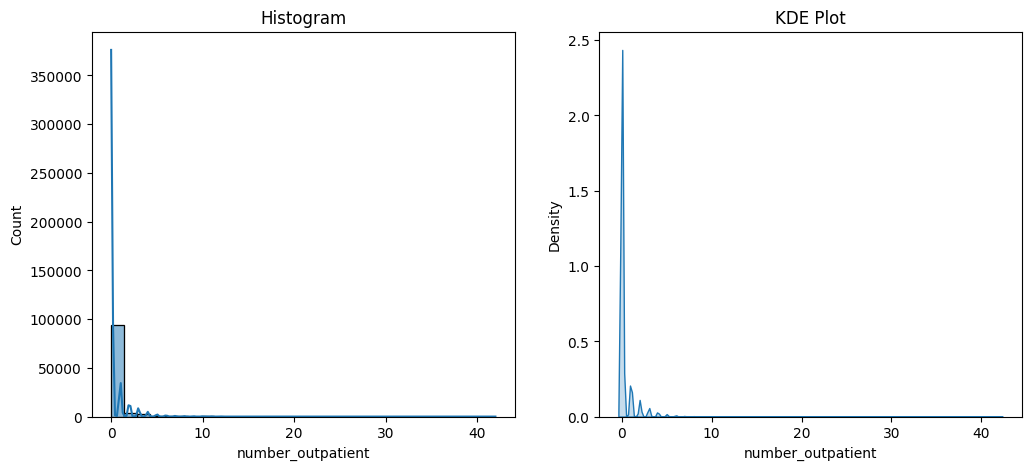

In [34]:
# number_outpatient

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['number_outpatient'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['number_outpatient'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='number_outpatient'>

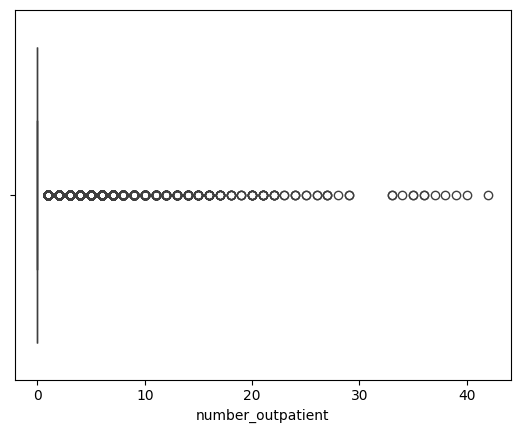

In [35]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['number_outpatient'])

In [36]:
# 3. Mean/Median

print(f"Mean : {df['number_outpatient'].mean()}")
print(f"Median : {df['number_outpatient'].median()}")

Mean : 0.36935715268360747
Median : 0.0


In [37]:
# 4. Filtering Outlier using IQR

Q1 = df['number_outpatient'].quantile(0.25)
Q3 = df['number_outpatient'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['number_outpatient'] < lower_bound) | (df['number_outpatient'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 16739


<Axes: xlabel='readmitted', ylabel='number_outpatient'>

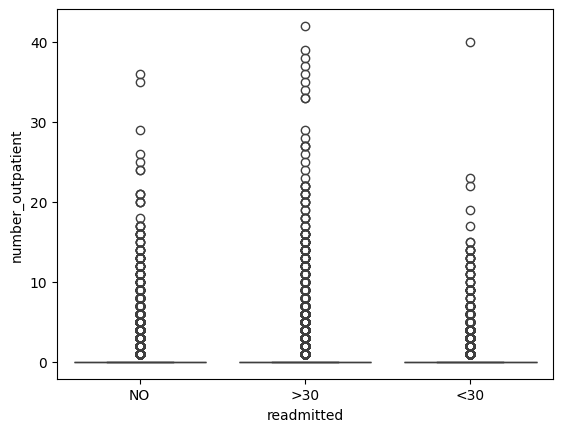

In [38]:
sns.boxplot(x='readmitted', y='number_outpatient', data=df)

#### number_emergency

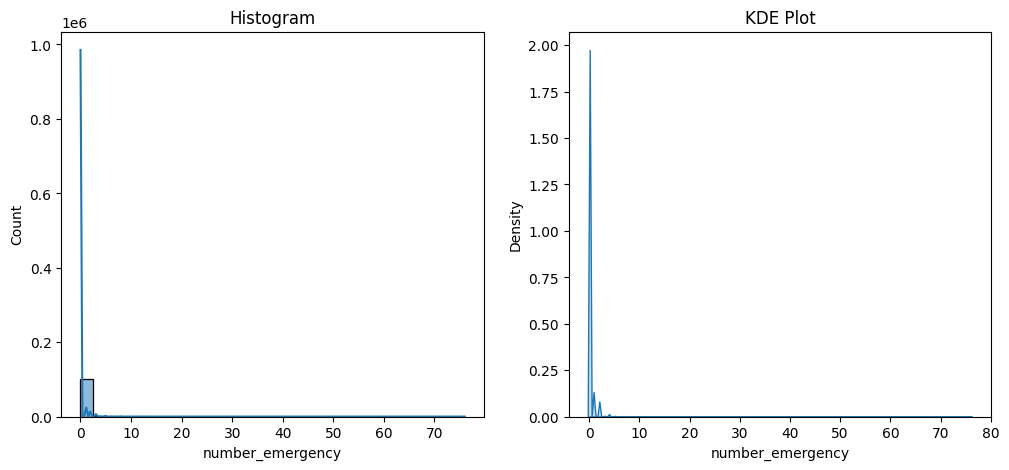

In [39]:
# number_emergency

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['number_emergency'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['number_emergency'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='number_emergency'>

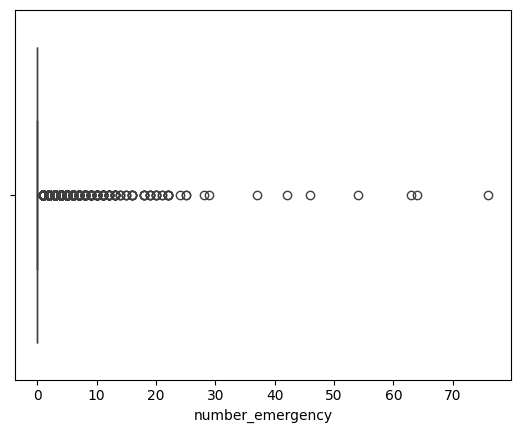

In [40]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['number_emergency'])

In [41]:
# 3. Mean/Median

print(f"Mean : {df['number_emergency'].mean()}")
print(f"Median : {df['number_emergency'].median()}")

Mean : 0.19783621248747127
Median : 0.0


In [42]:
# 4. Filtering Outlier using IQR

Q1 = df['number_emergency'].quantile(0.25)
Q3 = df['number_emergency'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['number_emergency'] < lower_bound) | (df['number_emergency'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 11383


<Axes: xlabel='readmitted', ylabel='number_emergency'>

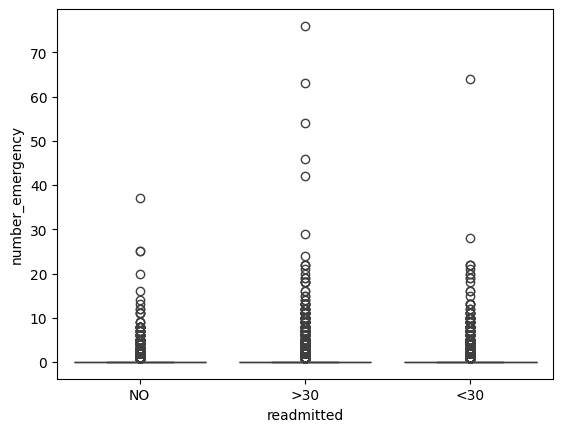

In [43]:
sns.boxplot(x='readmitted', y='number_emergency', data=df)

#### number_inpatient

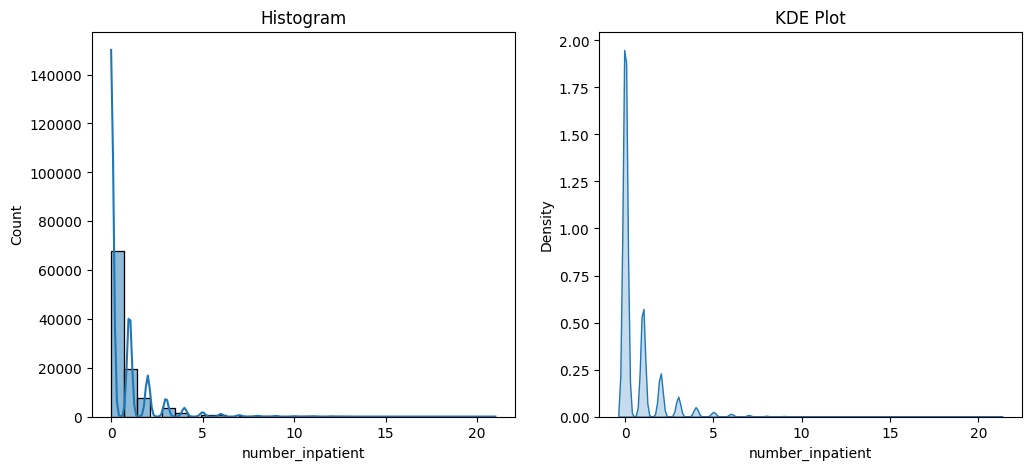

In [44]:
# number_inpatient

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['number_inpatient'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['number_inpatient'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='number_inpatient'>

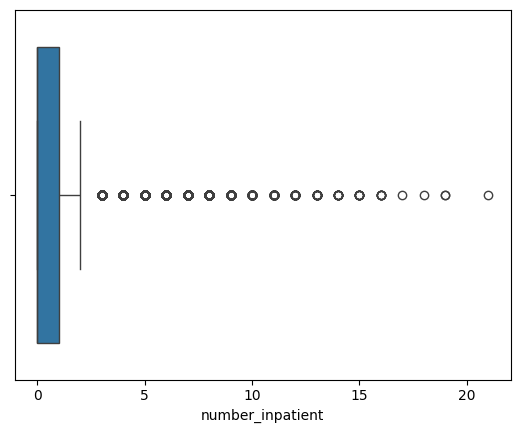

In [45]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['number_inpatient'])

In [46]:
# 3. Mean/Median

print(f"Mean : {df['number_inpatient'].mean()}")
print(f"Median : {df['number_inpatient'].median()}")

Mean : 0.635565906098304
Median : 0.0


In [47]:
# 4. Filtering Outlier using IQR

Q1 = df['number_inpatient'].quantile(0.25)
Q3 = df['number_inpatient'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['number_inpatient'] < lower_bound) | (df['number_inpatient'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 7049


<Axes: xlabel='readmitted', ylabel='number_inpatient'>

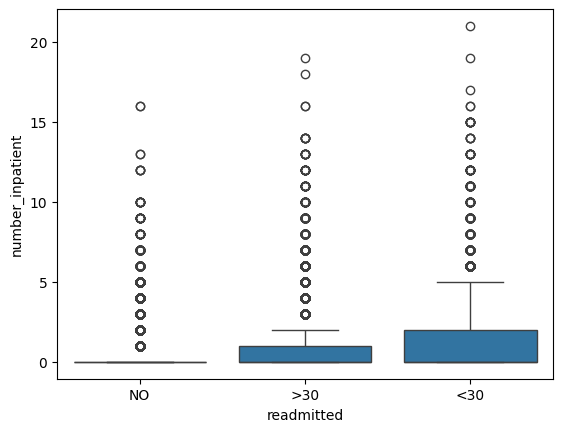

In [48]:
# Compare prior inpatient visit counts across readmission categories. 

sns.boxplot(x='readmitted', y='number_inpatient', data=df)

#### number_diagnoses

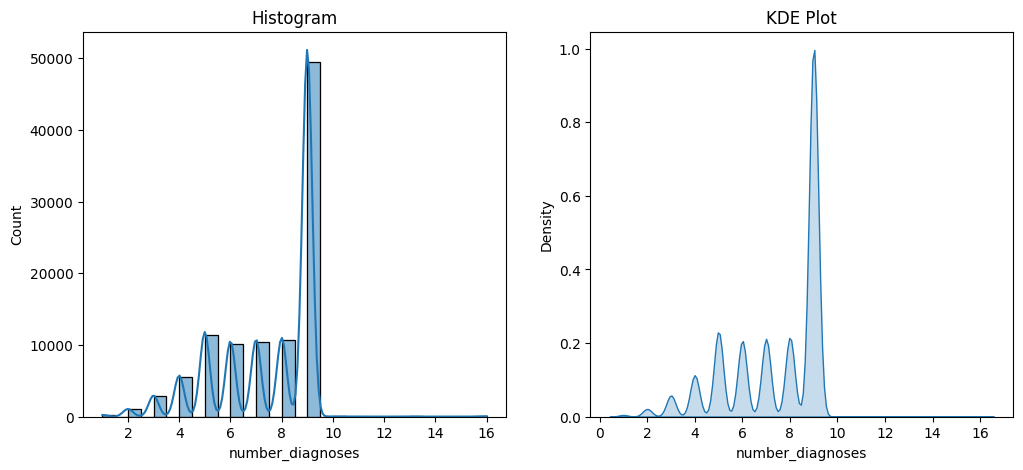

In [49]:
# number_diagnoses -> Number of problems that patient have

# 1. Distribution

fig , axes = plt.subplots(1,2, figsize=(12,5))

sns.histplot(df['number_diagnoses'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Histogram")

sns.kdeplot(df['number_diagnoses'], fill=True, ax=axes[1])
axes[1].set_title("KDE Plot")

plt.show()

<Axes: xlabel='number_diagnoses'>

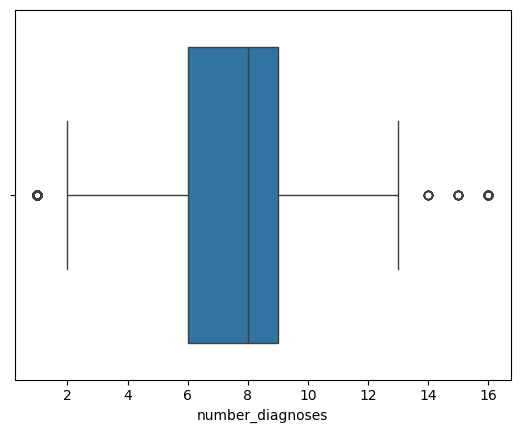

In [50]:
# 2. Boxplot / Outlier detection

sns.boxplot(x=df['number_diagnoses'])

In [51]:
# 3. Mean/Median

print(f"Mean : {df['number_diagnoses'].mean()}")
print(f"Median : {df['number_diagnoses'].median()}")

Mean : 7.422606764538254
Median : 8.0


In [52]:
# 4. Filtering Outlier using IQR

Q1 = df['number_diagnoses'].quantile(0.25)
Q3 = df['number_diagnoses'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers
outliers = df[(df['number_diagnoses'] < lower_bound) | (df['number_diagnoses'] > upper_bound)]

print(f"Total number of outliers: {outliers.shape[0]}")

Total number of outliers: 281


<Axes: xlabel='readmitted', ylabel='number_diagnoses'>

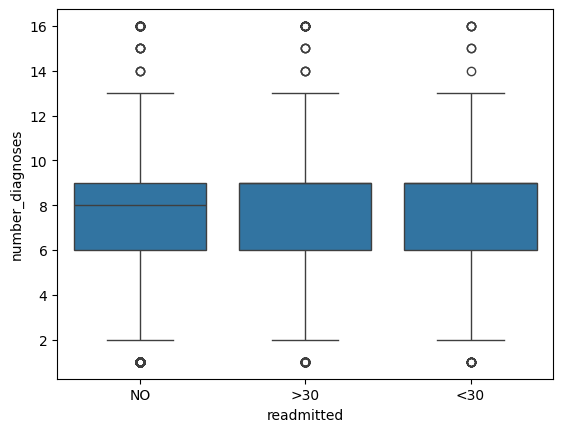

In [53]:
# Compare the number of diagnoses across readmission categories.

sns.boxplot(x='readmitted', y='number_diagnoses', data=df)

### Categorical Feature Analysis

In [54]:
# Important categorical columns
# ------------------------------
# gender
# race
# age
# admission_type
# discharge_disposition
# admission_source
# insulin
# diabetesMed
# change

#### gender

In [55]:
# gender

# 1. Value Counts
df['gender'].value_counts()

gender
Female     54708
Male       47055
Unknown        3
Name: count, dtype: int64

In [56]:
# 2. Crosstab

pd.crosstab(df['gender'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
gender,,,
Female,11.245156,35.676683,53.078160
Male,11.061524,34.060142,54.878334
Unknown,0.000000,0.000000,100.000000


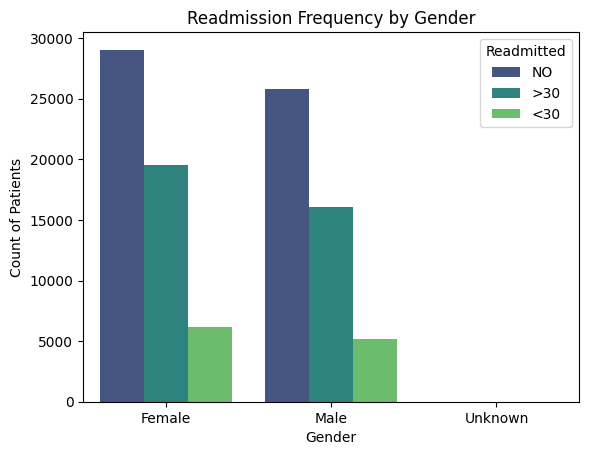

In [57]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='gender', hue='readmitted', palette='viridis')

plt.title('Readmission Frequency by Gender')
plt.xlabel('Gender')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

In [58]:
# Insights

# Readmission rates appear similar across genders in this descriptive comparison. Refer to the normalized crosstab for the actual percentages; the rates should not be assumed to be exactly equal.

#### race

In [59]:
# race

# 1. Value Counts
df['race'].value_counts()

race
Caucasian          76099
AfricanAmerican    19210
Unknown             2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

In [60]:
# 2. Crosstab

pd.crosstab(df['race'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
race,,,
AfricanAmerican,11.218116,34.534097,54.247788
Asian,10.140406,25.117005,64.742590
Caucasian,11.290556,35.643044,53.066400
Hispanic,10.407462,31.516937,58.075601
Other,9.628154,29.614874,60.756972
Unknown,8.271007,23.669160,68.059833


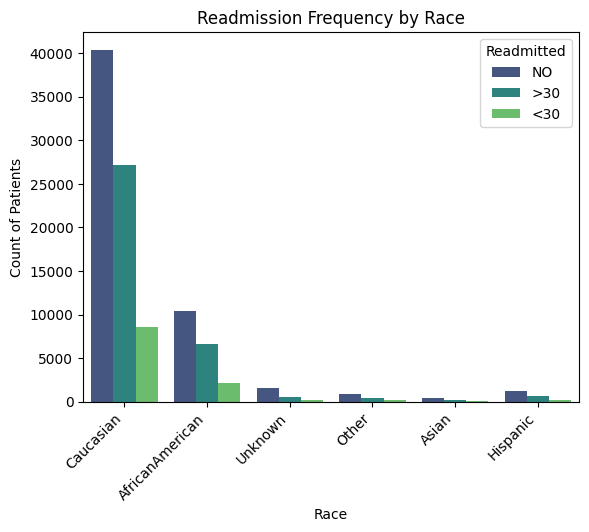

In [61]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='race', hue='readmitted', palette='viridis')

# Rotate the x-axis labels
plt.xticks(rotation=45, ha='right')

plt.title('Readmission Frequency by Race')
plt.xlabel('Race')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

In [62]:
# Insights

# The observed 30-day readmission rates vary across race categories, although some groups may have similar rates.
# The Unknown category has a different readmission rate and should be considered separately.
# Caucasian patients make up the largest proportion of encounters, so subgroup counts vary across race categories and should be considered when interpreting the percentages.

#### age

In [63]:
# age

# 1. Value Counts
df['age'].value_counts()

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

In [64]:
# 2. Crosstab

pd.crosstab(df['age'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
age,,,
[0-10),1.863354,16.149068,81.987578
[10-20),5.788712,32.416787,61.794501
[20-30),14.242607,30.778515,54.978877
[30-40),11.231788,31.443709,57.324503
[40-50),10.604027,33.846154,55.549819
[50-60),9.666203,34.289522,56.044274
[60-70),11.128408,35.124316,53.747276
[70-80),11.773055,36.347246,51.879699
[80-90),12.083503,36.186544,51.729953


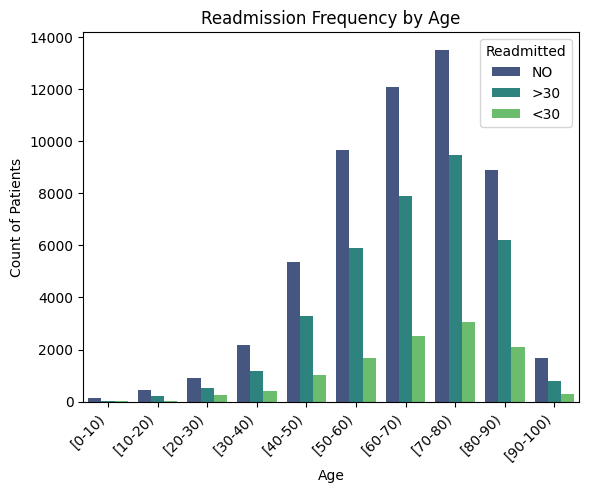

In [65]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='age', hue='readmitted', palette='viridis')


# Rotate the x-axis labels
plt.xticks(rotation=45, ha='right')

plt.title('Readmission Frequency by Age')
plt.xlabel('Age')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

#### admission_type

In [66]:
# admission_type

# 1. Value Counts
df['admission_type'].value_counts()

admission_type
Emergency        53990
Elective         18869
Urgent           18480
Unknown          10396
Trauma Center       21
Newborn             10
Name: count, dtype: int64

In [67]:
# 2. Crosstab

pd.crosstab(df['admission_type'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
admission_type,,,
Elective,10.392708,30.452064,59.155228
Emergency,11.522504,35.764030,52.713465
Newborn,10.000000,20.000000,70.000000
Trauma Center,0.000000,0.000000,100.000000
Unknown,10.657945,38.822624,50.519431
Urgent,11.179654,34.913420,53.906926


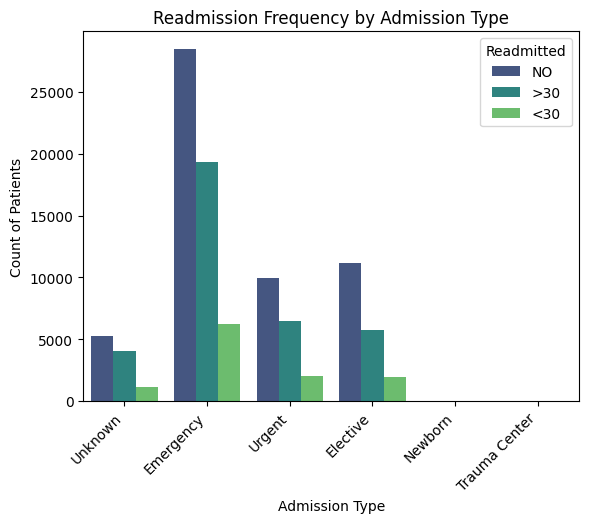

In [68]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='admission_type', hue='readmitted', palette='viridis')

# Rotate the x-axis labels
plt.xticks(rotation=45, ha='right')

plt.title('Readmission Frequency by Admission Type')
plt.xlabel('Admission Type')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

In [69]:
# Insights

# Approximately 50% of hospital encounters fall under the Emergency admission category, indicating that it represents a large proportion of the admission-type distribution.
# This describes the distribution of admission types and does not, by itself, explain 30-day readmission outcomes.

#### discharge_disposition

In [70]:
# discharge_disposition

# 1. Value Counts
df['discharge_disposition'].value_counts()

discharge_disposition
Discharged to home                                                                                           60234
Discharged/transferred to SNF                                                                                13954
Discharged/transferred to home with home health service                                                      12902
Unknown                                                                                                       4680
Discharged/transferred to another short term hospital                                                         2128
Discharged/transferred to another rehab fac including rehab units of a hospital .                             1993
Expired                                                                                                       1642
Discharged/transferred to another type of inpatient care institution                                          1184
Discharged/transferred to ICF                             

In [71]:
# 2. Crosstab

pd.crosstab(df['discharge_disposition'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
discharge_disposition,,,
Admitted as an inpatient to this hospital,42.857143,9.523810,47.619048
Discharged to home,9.300395,35.722350,54.977255
Discharged/transferred to ICF,12.760736,34.110429,53.128834
Discharged/transferred to SNF,14.662462,35.230042,50.107496
Discharged/transferred to a federal health care facility.,0.000000,20.000000,80.000000
Discharged/transferred to a long term care hospital.,7.281553,34.951456,57.766990
Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare.,14.583333,33.333333,52.083333
Discharged/transferred to another rehab fac including rehab units of a hospital .,27.696939,26.041144,46.261917
Discharged/transferred to another short term hospital,16.071429,31.390977,52.537594


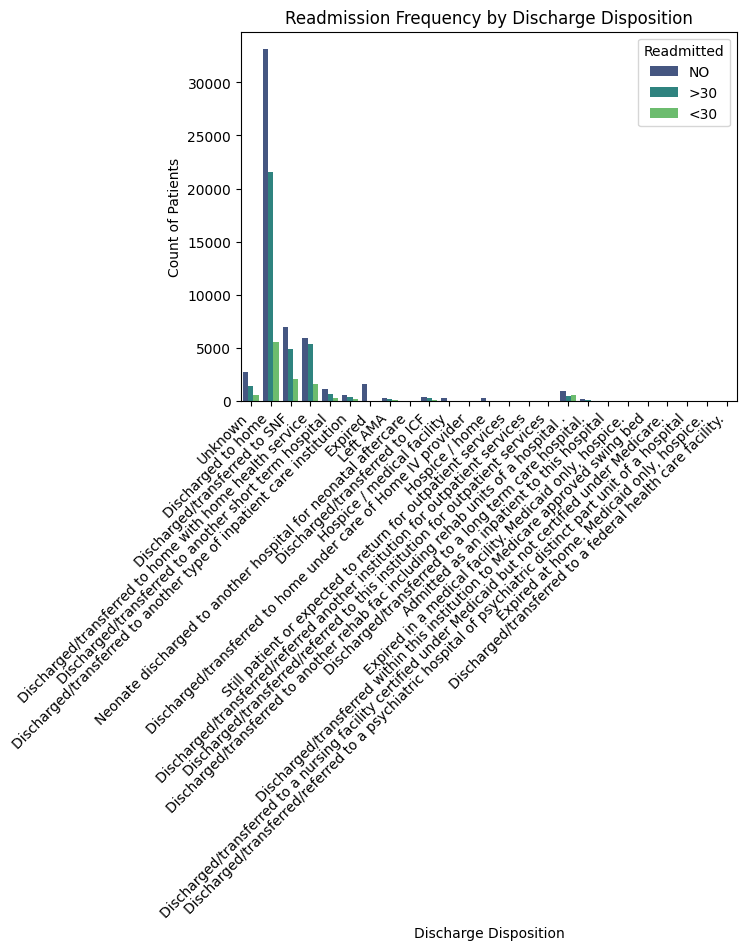

In [72]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='discharge_disposition', hue='readmitted', palette='viridis')

# Rotate the x-axis labels
plt.xticks(rotation=45, ha='right')

plt.title('Readmission Frequency by Discharge Disposition')
plt.xlabel('Discharge Disposition')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

In [73]:
# Insights

# Approximately 60% of hospital encounters are discharged to home.
# Within the "Discharged to home" group, approximately 9.3% of encounters are labelled <30, indicating readmission within 30 days.
# This percentage refers to encounters within the discharged-to-home group, not to all encounters in the dataset.

#### admission_source

In [74]:
# admission_source

# 1. Value Counts
df['admission_source'].value_counts()

admission_source
Emergency Room                                               57494
Physician Referral                                           29565
Unknown                                                       7067
Transfer from hospital                                        3187
Transfer from health care facility                            2264
Clinic Referral                                               1104
Transfer from a Skilled Nursing Facility (SNF)                 855
HMO Referral                                                   187
Court/Law Enforcement                                           16
Transfer from hospital inpt/same fac reslt in a sep claim       12
Transfer from critical access hospital                           8
Extramural Birth                                                 2
Normal Delivery                                                  2
Transfer from Ambulatory Surgery Center                          2
Sick Baby                                    

In [75]:
# 2. Crosstab

pd.crosstab(df['admission_source'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
admission_source,,,
Clinic Referral,10.054348,28.079710,61.865942
Court/Law Enforcement,12.500000,25.000000,62.500000
Emergency Room,11.688176,37.685672,50.626152
Extramural Birth,0.000000,0.000000,100.000000
HMO Referral,15.508021,31.016043,53.475936
Normal Delivery,0.000000,0.000000,100.000000
Physician Referral,10.586843,32.606122,56.807035
Sick Baby,0.000000,0.000000,100.000000
Transfer from Ambulatory Surgery Center,0.000000,0.000000,100.000000


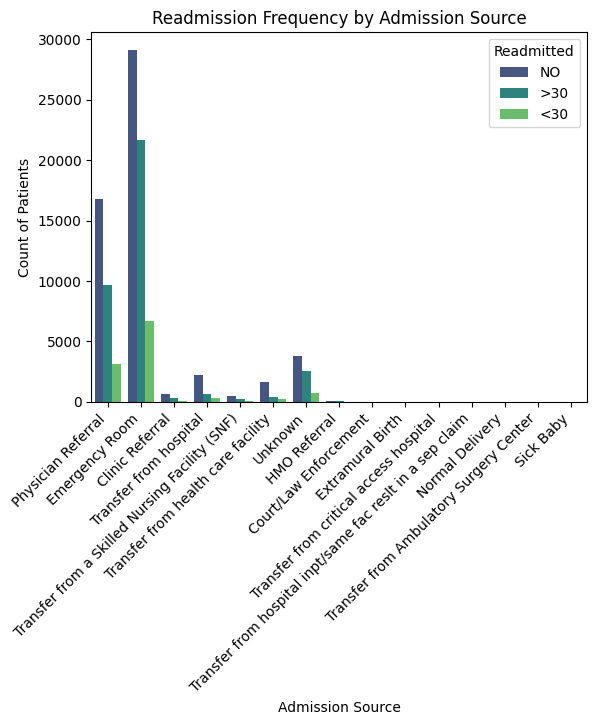

In [76]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='admission_source', hue='readmitted', palette='viridis')

# Rotate the x-axis labels
plt.xticks(rotation=45, ha='right')

plt.title('Readmission Frequency by Admission Source')
plt.xlabel('Admission Source')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

In [77]:
# Insights

# More than 55% of hospital encounters have the Emergency Room recorded as their admission source, making it a major category in the overall admission-source distribution.
# This percentage describes all encounters by admission source.
# The readmission rate within the Emergency Room group should be interpreted separately using the within-category percentages.

#### insulin

In [78]:
# insulin

# 1. Value Counts
df['insulin'].value_counts()

insulin
No        47383
Steady    30849
Down      12218
Up        11316
Name: count, dtype: int64

In [79]:
# 2. Crosstab

pd.crosstab(df['insulin'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
insulin,,,
Down,13.897528,38.893436,47.209036
No,10.037355,33.659751,56.302893
Steady,11.128400,33.978411,54.893189
Up,12.990456,38.547190,48.462354


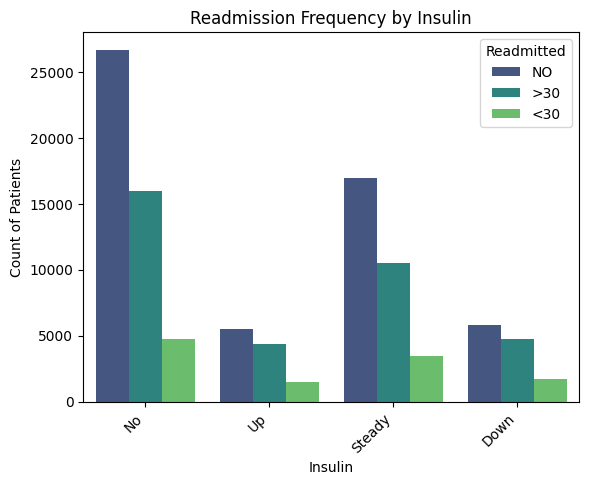

In [80]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='insulin', hue='readmitted', palette='viridis')

# Rotate the x-axis labels
plt.xticks(rotation=45, ha='right')

plt.title('Readmission Frequency by Insulin')
plt.xlabel('Insulin')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

In [81]:
# Insights

# Encounters with insulin dosage recorded as "Down" show a slightly higher percentage of 30-day readmission compared with some other insulin-status categories.
# "Down" represents a recorded medication change category.
# This is a descriptive association and does not establish that reducing insulin dosage causes readmission.

#### diabetesMed

In [82]:
# diabetesMed

# 1. Value Counts
df['diabetesMed'].value_counts()

diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64

In [83]:
# 2. Crosstab

pd.crosstab(df['diabetesMed'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
diabetesMed,,,
No,9.597060,30.880656,59.522283
Yes,11.626661,36.136952,52.236387


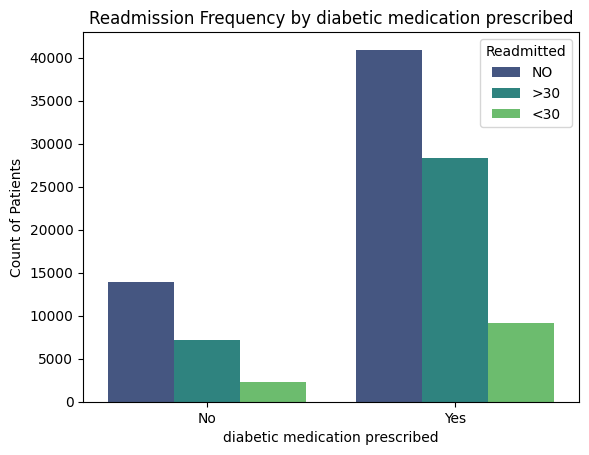

In [84]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='diabetesMed', hue='readmitted', palette='viridis')

plt.title('Readmission Frequency by diabetic medication prescribed')
plt.xlabel('diabetic medication prescribed')
plt.ylabel('Count of Patients')
plt.legend(title='Readmitted', loc='upper right')

plt.show()

#### change

In [85]:
# change

# 1. Value Counts
df['change'].value_counts()

change
No    54755
Ch    47011
Name: count, dtype: int64

In [86]:
# 2. Crosstab

pd.crosstab(df['change'], df['readmitted'], normalize='index')*100

readmitted,<30,>30,NO
change,,,
Ch,11.822765,36.740337,51.436898
No,10.590814,33.372295,56.036892


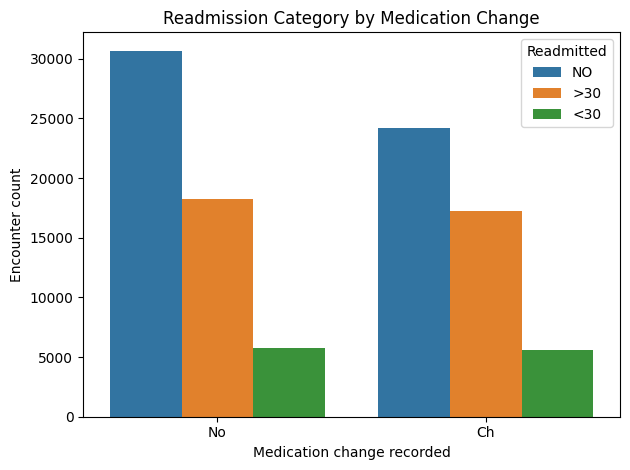

In [87]:
# 3. Countplot vs readmitted

sns.countplot(data=df, x='change', hue='readmitted')

plt.title('Readmission Category by Medication Change')
plt.xlabel('Medication change recorded')
plt.ylabel('Encounter count')
plt.legend(title='Readmitted')

plt.tight_layout()
plt.show()

### Correlation Analysis (Numerical)

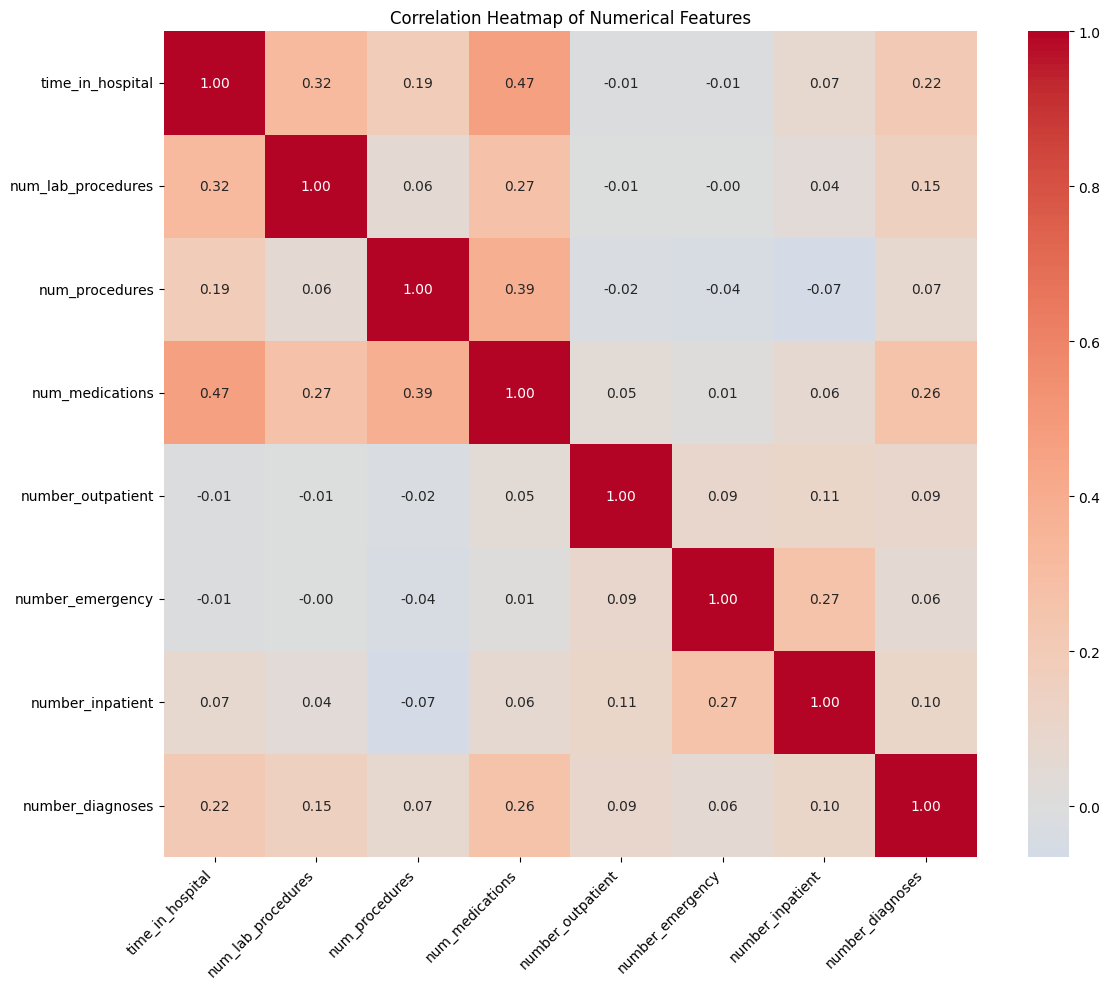

In [88]:
# 1. Define list of numerical columns
numeric_cols = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures', 
    'num_medications', 'number_outpatient', 'number_emergency', 
    'number_inpatient', 'number_diagnoses'
]

# 2. Calculating the correlation matrix
corr_matrix = df[numeric_cols].corr()

# 3. Creating the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", center=0)

# 4. Handling long labels
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

In [89]:
# Insights

# - A moderate positive correlation was observed between time_in_hospital and num_medications (0.47).

# - Treatment-related features, including lab tests, procedures, and medications, show some inter-correlation.

# - Emergency and inpatient visits show a positive correlation (0.27).

# - No very high pairwise correlations were observed among the selected numerical variables. This heatmap does not assess multicollinearity involving all one-hot-encoded or categorical predictors.

### Readmission Deep Dive (Important for Insight Extraction)

#### Age vs. Readmission (Categorical vs. Target)

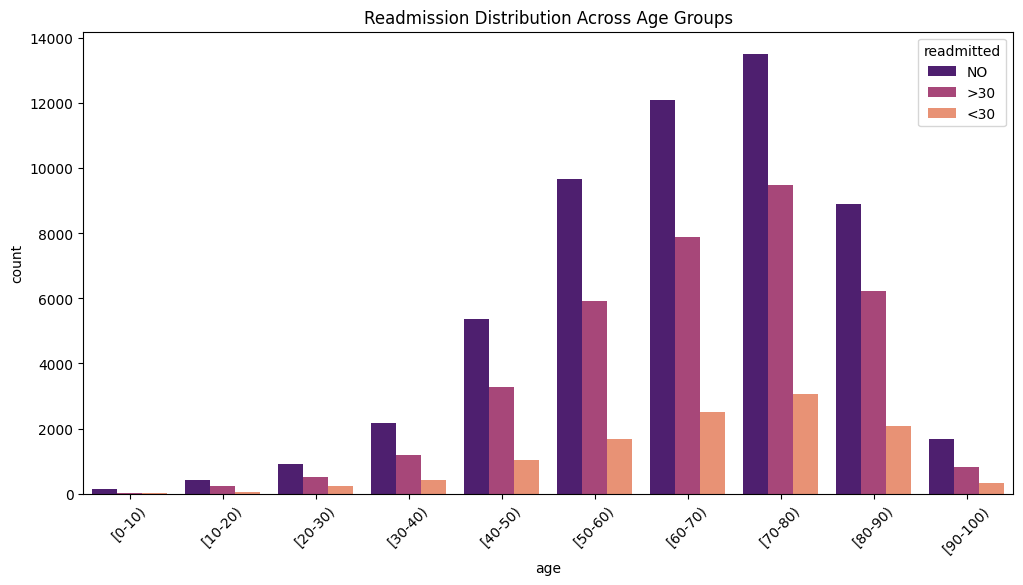

In [90]:
plt.figure(figsize=(12,6))
# Using a countplot with hue to see the breakdown
sns.countplot(data=df, x='age', hue='readmitted', palette='magma')
plt.title('Readmission Distribution Across Age Groups')
plt.xticks(rotation=45)
plt.show()

#### Insulin vs. Readmission (Treatment vs. Target)

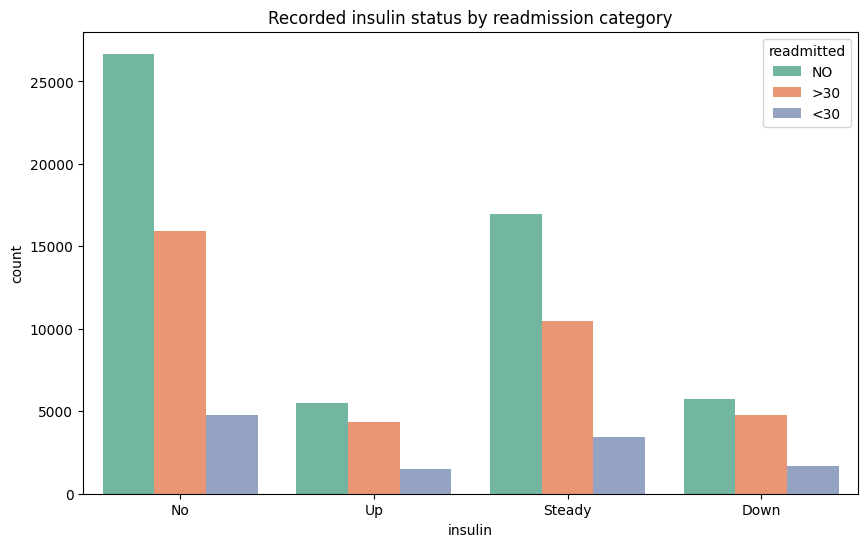

In [91]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='insulin', hue='readmitted', palette='Set2')
plt.title('Recorded insulin status by readmission category')
plt.show()

#### Time in Hospital vs. Readmission (Numerical vs. Target)

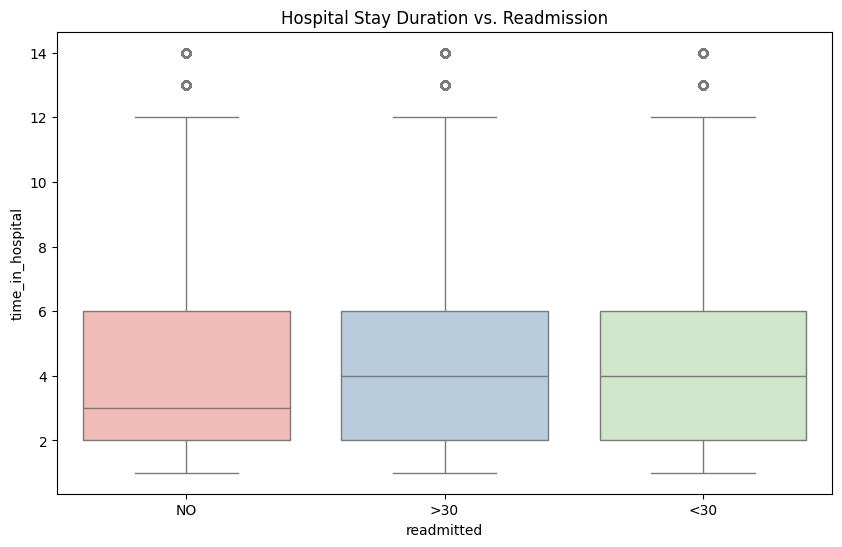

In [96]:
plt.figure(figsize=(10,6))
sns.boxplot(
  data=df,
  x='readmitted',
  y='time_in_hospital',
  hue='readmitted',
  palette='Pastel1',
  legend=False
)
plt.title('Hospital Stay Duration vs. Readmission')
plt.show()

#### Inpatient Visits vs. Readmission (Frequency vs. Target)

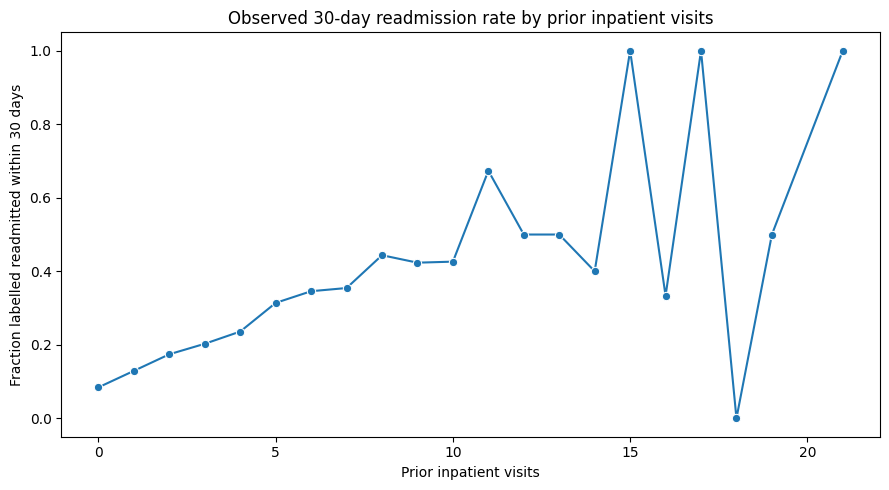

In [93]:
rate_by_inpatient_visits = (
    df.assign(readmitted_30d=df['readmitted'].eq('<30').astype('int8'))
      .groupby('number_inpatient')['readmitted_30d']
      .agg(encounters='size', readmission_rate='mean')
      .reset_index()
)

plt.figure(figsize=(9, 5))
sns.lineplot(data=rate_by_inpatient_visits,
             x='number_inpatient', y='readmission_rate', marker='o')
plt.ylabel('Fraction labelled readmitted within 30 days')
plt.xlabel('Prior inpatient visits')
plt.title('Observed 30-day readmission rate by prior inpatient visits')
plt.tight_layout()
plt.show()

### Outlier Detection

In [94]:
# Used Boxplot and IQR method in Numerical feature analysis, same as outlier detection

### Insights

In [95]:
# Final Insights

# - Encounters with more prior inpatient visits show an association with 30-day readmission; refer to the number_inpatient boxplot.

# - The insulin status category "Down" shows a slightly higher observed 30-day readmission percentage; refer to the insulin status analysis.

# - Emergency Room is the recorded admission source for more than 55% of encounters; refer to the admission-source distribution.

# - Approximately 60% of encounters are discharged to home. Within this group, about 9.3% are labelled <30; refer to the discharge-disposition analysis.

# - The [70-80] age group represents a large proportion of encounters; refer to the age distribution plot.

# - Caucasian is the most represented race category; refer to the race distribution plot.

# - time_in_hospital and num_medications show a moderate positive correlation (0.47); refer to the numerical correlation heatmap.

# - The target is imbalanced: approximately 11.16% of encounters are labelled <30 (class 1), while class 0 combines >30 and NO. Refer to the target count and percentage plots.